# 04 · Global XGBoost: tuning and validation results

Supports **Sections 6.6, 7.1–7.4 and 7.7** of the thesis, and prepares 7.5, 7.6 and 7.9. The models were trained
on Kaggle GPUs by the jobs in `kaggle_jobs/global_xgb/` (code in `src/global_xgb.py`); this notebook only reads
their outputs.

**Models.** Every model is an XGBoost that forecasts the 7 days after a forecast origin and has the horizon
(1–7 days ahead) as an input. A variant is an input set with a loss:

| Input set | Inputs | Columns |
|---|---|---|
| L | sales of the last 56 days | 57 |
| L+E | + inputs known in advance for the target day: weekday, events, SNAP, price | 66 |
| L+E+S | + inputs derived from the sales history: rolling means, zero share, days since the last sale, age | 75 |
| L+E+S+ID | + identifiers: item, department, category, store, state | 80 |
| L+E+S+ID+H | + recent sales of higher levels of the hierarchy: the item in all stores, the department in the store, the whole store (means of 7 and 28 days and their ratio) | 89 |

- **Global variants (11):** L, L+E and L+E+S with the MSE, Poisson and Tweedie loss, and L+E+S+ID and
  L+E+S+ID+H with the loss that was best for L+E+S. L+E+S+ID+H was added last, after the test window had
  been opened for the other models; it was tuned on the validation window in the same way. It is reported
  as an additional step of the input analysis; the **main model** of the thesis is the best of the ten
  variants fixed before the test window was opened. One model for all 30,490 series, about 13.1 million training rows (weekly origins,
  2 of the 7 horizons drawn at random per origin).
- **Partially global models (Section 7.2):** one model per store (10), per store and category (30) and per
  demand class (4), trained on the rows of their own series only.
- **Recursive strategy (Section 7.7):** a model that forecasts one day ahead and is applied 7 times, each
  forecast being fed back as if it were the sales of its day.

**Tuning.** Hyperopt (TPE), 30 trials per global variant. A trial trains on targets up to 24.04.2016. with early
stopping on the RMSE of the validation forecasts; Hyperopt minimises their WRMSSE over the 7
hierarchy levels of the thesis (total, state, store, category, store × category, item, item × store), the
measure of all results below. The partially global and
the recursive models are not tuned: they take the hyperparameters of a tuned global variant and only their
number of rounds is chosen by early stopping.

**Scope.** All scores below are for the validation window 25.04.–22.05.2016., forecast 7 days at a time from
4 weekly origins. The hyperparameters were chosen on this window, so the scores of the tuned models are
optimistic; the test window is scored only in notebook 06.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import m5_data as m5
import metrics as M
from plot_style import BLUE_RAMP, CONTEXT, INK_SECONDARY, SERIES, apply_style, label_line_end, savefig

apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
RUNS = m5.PROCESSED_DIR / "global_xgb"  # kernel outputs, fetched by kaggle_jobs/global_xgb/fetch.py
RESULTS = ROOT / "results" / "global_xgb"
BENCH = ROOT / "results" / "benchmarks"

INPUTS = {"L": "L", "LE": "L+E", "LES": "L+E+S", "LESID": "L+E+S+ID", "LESIDH": "L+E+S+ID+H"}
LOSSES = {"mse": "MSE", "poisson": "Poisson", "tweedie": "Tweedie"}
KINDS = {"": "global", "per_store": "per store", "per_store_cat": "per store × category", "per_class": "per demand class",
         "recursive": "recursive"}
LEVEL_NAMES = {1: "Total", 2: "State", 3: "Store", 4: "Category", 5: "Department", 6: "State × category",
               7: "State × department", 8: "Store × category", 9: "Store × department", 10: "Item",
               11: "Item × state", 12: "Item × store"}
CLASSES = ["smooth", "erratic", "intermittent", "lumpy"]


def parse(variant):
    inputs, loss, *rest = variant.split("_", 2)
    return inputs, loss, rest[0] if rest else ""


def label(variant):
    inputs, loss, kind = parse(variant)
    return f"{INPUTS[inputs]} · {LOSSES[loss]}" + (f" · {KINDS[kind]}" if kind else "")


def wrmsse_levels(rec):
    # WRMSSE over the 7 levels of the thesis, from the WRMSSE of each level stored by the Kaggle jobs
    return float(np.mean([rec["wrmsse_by_level"][str(k)] for k in m5.EVAL_LEVELS]))


best, fc = {}, {}
for f in sorted(RUNS.glob("*/*/best.json")):
    b = json.loads(f.read_text())
    b["wrmsse"] = wrmsse_levels(b)  # the same as the WRMSSE stored by the jobs, which were tuned on the 7 levels
    best[b["variant"]] = b
    fc[b["variant"]] = np.load(f.parent / "valid_forecast.npy")
GLOBAL = [v for v in best if parse(v)[2] == ""]
GLOBAL.sort(key=lambda v: (list(INPUTS).index(parse(v)[0]), list(LOSSES).index(parse(v)[1])))
EXTRA = "LESIDH_tweedie"  # added after the test window had been opened: an additional step, not the main model
TOP = min([v for v in GLOBAL if v != EXTRA], key=lambda v: best[v]["wrmsse"])  # the main model
print(f"{len(GLOBAL)} global variants, {len(best) - len(GLOBAL)} other models; main model: {label(TOP)} "
      f"(WRMSSE {best[TOP]['wrmsse']:.3f}); added later: {label(EXTRA)} (WRMSSE {best[EXTRA]['wrmsse']:.3f})")

ev = M.Evaluator.for_origin(m5.TRAIN_END, (m5.TRAIN_END + 1, m5.VALID_END))
stats = pd.read_parquet(m5.PROCESSED_DIR / "series_stats_train.parquet")
bm = np.load(m5.PROCESSED_DIR / "forecasts" / "benchmarks.npz")
BM_NAMES = {"naive": "Naive", "snaive": "Seasonal naive", "mean": "Mean", "croston": "Croston", "sba": "SBA",
            "tsb": "TSB", "adida": "ADIDA", "ses": "SES",
         "ses_opt": "SES (optimised)", "sba_opt": "SBA (optimised)", "tsb_opt": "TSB (optimised)"}
bench = {name: bm[f"valid_{m}"] for m, name in BM_NAMES.items()}

11 global variants, 8 other models; main model: L+E+S+ID · Tweedie (WRMSSE 0.556); added later: L+E+S+ID+H · Tweedie (WRMSSE 0.539)


## 1. Tuning (Section 6.6)

Search space, the same for every variant:

| Hyperparameter | Range | Scale |
|---|---|---|
| `learning_rate` | 0.03 – 0.15 | log |
| `max_depth` | 4 – 12 | integer |
| `min_child_weight` | 1 – 300 | log |
| `subsample` | 0.5 – 1.0 | linear |
| `colsample_bytree` | 0.5 – 1.0 | linear |
| `reg_lambda` | 0.1 – 100 | log |
| `tweedie_variance_power` (Tweedie only) | 1.05 – 1.6 | linear |

Fixed: `tree_method="hist"`, `max_bin=256`, at most 1,500 rounds, early stopping after 30 rounds without
improvement. Forecasts below zero (possible with the MSE loss) are set to zero.

In [2]:
HYPER = ["learning_rate", "max_depth", "min_child_weight", "subsample", "colsample_bytree", "reg_lambda",
         "tweedie_variance_power"]
trials = {v: pd.DataFrame(json.loads((RESULTS / v / "trials.json").read_text())) for v in GLOBAL}
tuning = pd.DataFrame({label(v): {"trials": len(trials[v]), "failed": int((trials[v]["status"] != "ok").sum()),
                                  "GPU hours": trials[v]["seconds"].sum() / 3600, "rounds": best[v]["rounds"],
                                  **{h: best[v]["params"].get(h, np.nan) for h in HYPER}} for v in GLOBAL}).T
tuning.to_csv(RESULTS / "tuning_summary.csv")
print(f"tuning: {tuning['trials'].sum():.0f} trials, {tuning['GPU hours'].sum():.1f} GPU hours in total")
tuning.style.format("{:.3f}").format("{:.0f}", subset=["trials", "failed", "rounds", "max_depth"]).format(
    "{:.2f}", subset=["GPU hours"], na_rep="")

tuning: 330 trials, 11.6 GPU hours in total


,trials,failed,GPU hours,rounds,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda,tweedie_variance_power
L · MSE,30,0,0.60,308,0.043,11,1.115,0.984,0.993,0.103,nan
L · Poisson,30,0,1.46,312,0.084,8,6.063,0.965,0.511,0.478,nan
L · Tweedie,30,0,0.76,400,0.148,4,232.209,0.874,0.759,0.114,1.453
L+E · MSE,30,0,0.52,212,0.061,11,1.082,0.992,0.795,0.540,nan
L+E · Poisson,30,0,1.91,790,0.036,9,12.785,0.924,0.622,25.812,nan
L+E · Tweedie,30,0,0.87,178,0.114,6,269.845,0.995,0.805,0.167,1.451
L+E+S · MSE,30,0,0.69,187,0.045,12,1.091,0.848,0.781,0.289,nan
L+E+S · Poisson,30,0,1.70,213,0.107,11,26.882,0.995,0.728,10.592,nan
L+E+S · Tweedie,30,0,0.94,108,0.140,10,1.727,0.701,0.640,17.714,1.263
L+E+S+ID · Tweedie,30,0,1.08,161,0.083,9,128.354,0.686,0.655,0.252,1.062


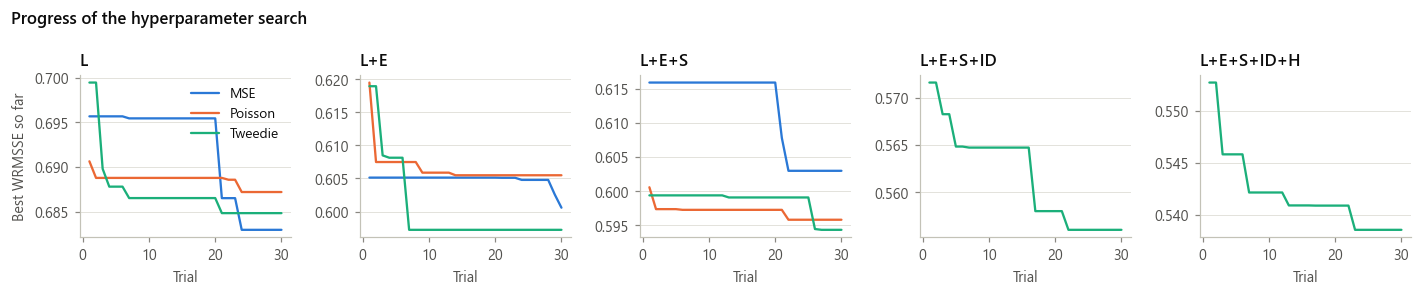

In [3]:
sets = [i for i in INPUTS if any(parse(v)[0] == i for v in GLOBAL)]
fig, axes = plt.subplots(1, len(sets), figsize=(2.6 * len(sets), 2.7), sharex=True)
for ax, i in zip(axes, sets):
    for (loss, name), color in zip(LOSSES.items(), SERIES):
        v = f"{i}_{loss}"
        if v in trials:
            ax.plot(np.arange(1, len(trials[v]) + 1), trials[v]["wrmsse"].cummin(), color=color, label=name)
    ax.set_title(INPUTS[i])
    ax.set_xlabel("Trial")
axes[0].set_ylabel("Best WRMSSE so far")
axes[0].legend(loc="upper right")
fig.suptitle("Progress of the hyperparameter search", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
savefig(fig, "tuning_progress", subdir="global_xgb")
plt.show()

## 2. Global variants against the classical methods (Sections 7.1, 7.3, 7.4)

RMSSE to sME are means over the 30,490 item-store series; WRMSSE covers the 7 hierarchy levels.

In [4]:
def measures(forecasts):
    out = {}
    for name, f in forecasts.items():
        b = ev.bottom(f)
        out[name] = {"WRMSSE": ev.wrmsse(f)["all"], "RMSSE mean": b.rmsse.mean(), "RMSSE median": b.rmsse.median(),
                     "MASE": b.mase.mean(), "sME": b.sme.mean(), "above": b.above.mean(), "below": b.below.mean()}
    return pd.DataFrame(out).T


summary = pd.concat([measures({label(v): fc[v] for v in GLOBAL}), measures(bench).sort_values("WRMSSE")])
summary.to_csv(RESULTS / "summary_valid.csv")
summary.style.format("{:.3f}").highlight_min(axis=0, subset=["WRMSSE", "RMSSE mean", "RMSSE median", "MASE"],
                                             props="font-weight: bold")

,WRMSSE,RMSSE mean,RMSSE median,MASE,sME,above,below
L · MSE,0.683,0.748,0.703,1.093,0.009,0.667,0.333
L · Poisson,0.687,0.748,0.702,1.094,0.008,0.667,0.333
L · Tweedie,0.685,0.749,0.703,1.088,0.001,0.669,0.331
L+E · MSE,0.601,0.747,0.702,1.088,0.005,0.666,0.334
L+E · Poisson,0.605,0.746,0.700,1.086,0.001,0.667,0.333
L+E · Tweedie,0.597,0.747,0.703,1.083,-0.001,0.668,0.332
L+E+S · MSE,0.603,0.742,0.696,1.069,-0.021,0.668,0.332
L+E+S · Poisson,0.596,0.741,0.695,1.065,-0.020,0.669,0.331
L+E+S · Tweedie,0.594,0.741,0.695,1.064,-0.021,0.670,0.330
L+E+S+ID · Tweedie,0.556,0.739,0.693,1.052,-0.040,0.668,0.332


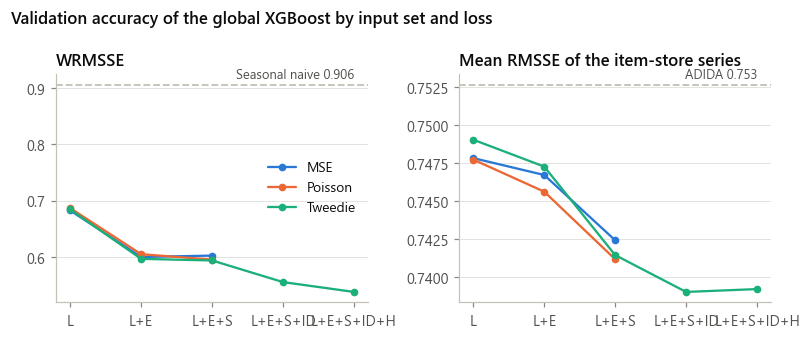

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.1))
x = np.arange(len(sets))
for ax, col, ref in zip(axes, ["WRMSSE", "RMSSE mean"], ["Seasonal naive", "ADIDA"]):
    for (loss, name), color in zip(LOSSES.items(), SERIES):
        pts = [(k, summary.loc[label(f"{i}_{loss}"), col]) for k, i in enumerate(sets) if f"{i}_{loss}" in fc]
        ax.plot(*zip(*pts), color=color, marker="o", ms=4, label=name)
    ax.axhline(summary.loc[ref, col], color=CONTEXT, lw=1.2, ls="--")
    ax.annotate(f"{ref} {summary.loc[ref, col]:.3f}", (x[-1], summary.loc[ref, col]), xytext=(0, 4),
                textcoords="offset points", ha="right", color=INK_SECONDARY, fontsize=8.5)
    ax.set_xticks(x, [INPUTS[i] for i in sets])
    ax.set_title(col if col == "WRMSSE" else "Mean RMSSE of the item-store series")
axes[0].legend(loc="center right")
fig.suptitle("Validation accuracy of the global XGBoost by input set and loss", x=0.01, ha="left", fontsize=11,
             fontweight="semibold")
fig.tight_layout()
savefig(fig, "variants_valid", subdir="global_xgb")
plt.show()

### Paired comparison with the best classical methods

For each pair, the mean difference of the per-series RMSSE (negative: the XGBoost variant is better) and the
share of the 30,490 series on which the variant has the lower RMSSE. The formal tests are in notebook 06.

In [6]:
rmsse = pd.DataFrame({**{v: ev.bottom(f).rmsse for v, f in fc.items()}, **{m: ev.bottom(f).rmsse for m, f in bench.items()}})
tw = [v for v in GLOBAL if parse(v)[1] == parse(TOP)[1]]
pairs = pd.DataFrame([{"variant": label(v), "against": m, "mean difference": (rmsse[v] - rmsse[m]).mean(),
                       "share of series better": (rmsse[v] < rmsse[m]).mean(),
                       "share of series equal": (rmsse[v] == rmsse[m]).mean()}
                      for v in tw for m in ["ADIDA", "TSB", "Seasonal naive"]]).set_index(["variant", "against"])
pairs.to_csv(RESULTS / "pairs_vs_benchmarks_valid.csv")
pairs

mean difference  share of series better  \
variant              against                                                   
L · Tweedie          ADIDA                    -0.004                   0.499   
                     TSB                      -0.006                   0.601   
                     Seasonal naive           -0.262                   0.954   
L+E · Tweedie        ADIDA                    -0.005                   0.511   
                     TSB                      -0.008                   0.609   
                     Seasonal naive           -0.264                   0.954   
L+E+S · Tweedie      ADIDA                    -0.011                   0.588   
                     TSB                      -0.014                   0.678   
                     Seasonal naive           -0.270                   0.954   
L+E+S+ID · Tweedie   ADIDA                    -0.014                   0.612   
                     TSB                      -0.016                   0.698   
                     Seasonal naive           -0.272                   0.955   
L+E+S+ID+H · Tweedie ADIDA                    -0.013                   0.610   
                     TSB                      -0.016                   0.697   
                     Seasonal naive           -0.272                   0.954   

                                     share of series equal  
variant              against                                
L · Tweedie          ADIDA                           0.000  
                     TSB                             0.000  
                     Seasonal naive                  0.000  
L+E · Tweedie        ADIDA                           0.000  
                     TSB                             0.000  
                     Seasonal naive                  0.000  
L+E+S · Tweedie      ADIDA                           0.000  
                     TSB                             0.000  
                     Seasonal naive                  0.000  
L+E+S+ID · Tweedie   ADIDA                           0.000  
                     TSB                             0.000  
                     Seasonal naive                  0.000  
L+E+S+ID+H · Tweedie ADIDA                           0.000  
                     TSB                             0.000  
                     Seasonal naive                  0.000

## 3. Accuracy by hierarchy level (Section 7.6)

In [7]:
levels = pd.DataFrame({**{label(v): ev.wrmsse(fc[v]) for v in GLOBAL}, **{m: ev.wrmsse(f) for m, f in bench.items()}}).T
levels = levels.drop(columns="all")
levels.columns = levels.columns.astype(int)
levels.to_csv(RESULTS / "wrmsse_by_level_valid.csv")
levels.rename(columns=LEVEL_NAMES).T.style.format("{:.3f}").highlight_min(axis=1, props="font-weight: bold")

,L · MSE,L · Poisson,L · Tweedie,L+E · MSE,L+E · Poisson,L+E · Tweedie,L+E+S · MSE,L+E+S · Poisson,L+E+S · Tweedie,L+E+S+ID · Tweedie,L+E+S+ID+H · Tweedie,Naive,Seasonal naive,Mean,Croston,SBA,TSB,ADIDA,SES,SES (optimised),SBA (optimised),TSB (optimised)
Total,0.548,0.552,0.538,0.394,0.403,0.371,0.389,0.379,0.373,0.373,0.329,2.032,0.780,1.214,1.134,1.180,1.134,1.141,1.135,1.142,1.206,1.136
State,0.606,0.612,0.605,0.489,0.498,0.484,0.489,0.482,0.480,0.436,0.415,1.954,0.819,1.221,1.117,1.157,1.118,1.122,1.120,1.130,1.182,1.123
Store,0.689,0.696,0.700,0.591,0.599,0.597,0.605,0.600,0.598,0.514,0.502,1.875,0.857,1.327,1.108,1.147,1.110,1.114,1.112,1.125,1.172,1.118
Category,0.588,0.592,0.580,0.466,0.471,0.451,0.462,0.447,0.442,0.410,0.372,1.972,0.822,1.204,1.136,1.179,1.135,1.139,1.136,1.143,1.201,1.136
Store × category,0.723,0.729,0.732,0.653,0.658,0.657,0.663,0.655,0.655,0.568,0.563,1.800,0.914,1.283,1.093,1.122,1.092,1.094,1.094,1.105,1.142,1.098
Item,0.808,0.810,0.815,0.796,0.795,0.801,0.798,0.794,0.797,0.781,0.779,1.348,1.050,1.174,0.924,0.926,0.904,0.906,0.905,0.912,0.929,0.906
Item × store,0.819,0.820,0.825,0.816,0.815,0.820,0.815,0.813,0.816,0.810,0.809,1.202,1.101,0.956,0.851,0.849,0.846,0.844,0.847,0.855,0.854,0.852


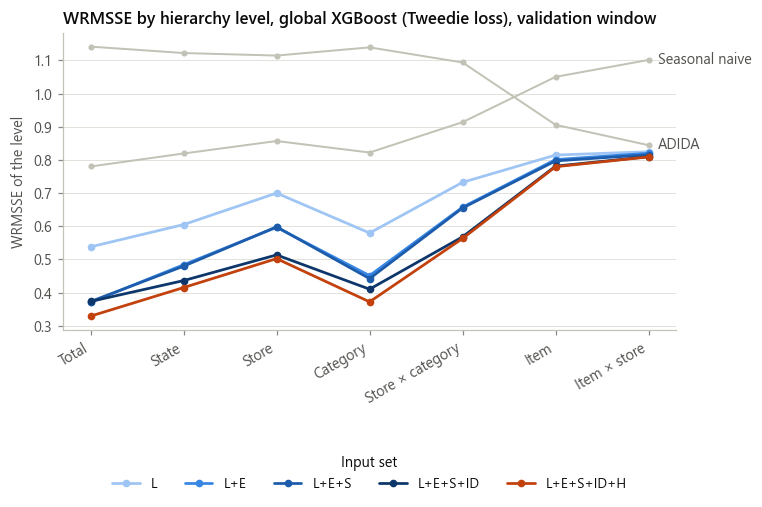

In [8]:
x = np.arange(len(levels.columns))
fig, ax = plt.subplots(figsize=(7.2, 3.5))
for m in ["Seasonal naive", "ADIDA"]:
    ax.plot(x, levels.loc[m], color=CONTEXT, lw=1.3, marker="o", ms=3)
    label_line_end(ax, x[-1], levels.loc[m].iloc[-1], m)
for v, color in zip(tw, [BLUE_RAMP[1], BLUE_RAMP[3], BLUE_RAMP[5], BLUE_RAMP[7], "#c2410c"]):
    ax.plot(x, levels.loc[label(v)], color=color, marker="o", ms=4, lw=1.8, label=INPUTS[parse(v)[0]])
ax.set_xticks(x, [LEVEL_NAMES[k] for k in levels.columns], rotation=30, ha="right")
ax.set_xlim(-0.3, x[-1] + 0.3)
ax.set_title(f"WRMSSE by hierarchy level, global XGBoost ({LOSSES[parse(TOP)[1]]} loss), validation window")
ax.set_ylabel("WRMSSE of the level")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.38), ncols=5, title="Input set")
savefig(fig, "wrmsse_by_level_valid", subdir="global_xgb")
plt.show()

## 4. Accuracy by demand class (Section 7.5)

Mean RMSSE of the item-store series by Syntetos–Boylan–Croston class (training window, notebook 01).

In [9]:
cls = stats["sbc_class"].astype(str).to_numpy()
cols = GLOBAL + ["TSB", "ADIDA", "Seasonal naive"]
by_class = rmsse[cols].groupby(cls).mean().T[CLASSES]
by_class["all"] = rmsse[cols].mean()
by_class.index = [label(v) if v in best else v for v in by_class.index]
by_class.loc["series"] = [*(pd.Series(cls).value_counts()[CLASSES]), len(cls)]
by_class.to_csv(RESULTS / "rmsse_by_class_valid.csv")
by_class.style.format("{:.3f}").format("{:,.0f}", subset=pd.IndexSlice["series", :]).highlight_min(
    axis=0, subset=pd.IndexSlice[by_class.index[:-1], :], props="font-weight: bold")

,smooth,erratic,intermittent,lumpy,all
L · MSE,0.711,0.664,0.765,0.704,0.748
L · Poisson,0.712,0.666,0.765,0.703,0.748
L · Tweedie,0.718,0.669,0.766,0.705,0.749
L+E · MSE,0.708,0.662,0.764,0.703,0.747
L+E · Poisson,0.707,0.660,0.763,0.701,0.746
L+E · Tweedie,0.712,0.665,0.765,0.703,0.747
L+E+S · MSE,0.708,0.661,0.759,0.701,0.742
L+E+S · Poisson,0.707,0.661,0.758,0.699,0.741
L+E+S · Tweedie,0.708,0.661,0.758,0.700,0.741
L+E+S+ID · Tweedie,0.703,0.657,0.756,0.697,0.739


## 5. Partially global models (Section 7.2)

The series are split into groups and each group gets its own model, trained on exactly the rows that the
global model has for these series. The hyperparameters are those of the global variant in the first column;
the number of rounds is chosen for each group by early stopping. The models per series and the global model
trained on 1,000 series are in notebook 05.

In [10]:
KEEP = [1, 3, 8, 12]
rows = []
for v in sorted(best, key=lambda v: (list(INPUTS).index(parse(v)[0]), list(KINDS).index(parse(v)[2]))):
    inputs, loss, kind = parse(v)
    if kind == "recursive" or (kind == "" and not any(parse(u)[:2] == (inputs, loss) and parse(u)[2].startswith("per") for u in best)):
        continue
    w = ev.wrmsse(fc[v])
    groups = best[v].get("groups", [])
    rows.append({"hyperparameters of": f"{INPUTS[inputs]} · {LOSSES[loss]}", "pooling": KINDS[kind], "models": max(len(groups), 1),
                 "rounds": f"{min(g['rounds'] for g in groups)}–{max(g['rounds'] for g in groups)}" if groups else str(best[v]["rounds"]),
                 "WRMSSE": w["all"], **{LEVEL_NAMES[k]: w[k] for k in KEEP}, "RMSSE mean": rmsse[v].mean()})
pooling = pd.DataFrame(rows).set_index(["hyperparameters of", "pooling"])
pooling.to_csv(RESULTS / "pooling_valid.csv")
pooling

models  rounds  WRMSSE  Total  Store  \
hyperparameters of pooling                                                      
L+E+S · Tweedie    global                     1     108   0.594  0.373  0.598   
                   per store                 10   32–59   0.606  0.461  0.535   
                   per store × category      30  21–110   0.630  0.519  0.574   
                   per demand class           4   28–46   0.617  0.423  0.618   
L+E+S+ID · Tweedie global                     1     161   0.556  0.373  0.514   
                   per store                 10  46–115   0.571  0.415  0.509   
                   per store × category      30  24–103   0.595  0.451  0.548   
                   per demand class           4  62–116   0.568  0.394  0.530   

                                         Store × category  Item × store  \
hyperparameters of pooling                                                
L+E+S · Tweedie    global                           0.655         0.816   
                   per store                        0.611         0.818   
                   per store × category             0.610         0.818   
                   per demand class                 0.669         0.817   
L+E+S+ID · Tweedie global                           0.568         0.810   
                   per store                        0.566         0.812   
                   per store × category             0.591         0.814   
                   per demand class                 0.582         0.809   

                                         RMSSE mean  
hyperparameters of pooling                           
L+E+S · Tweedie    global                     0.741  
                   per store                  0.742  
                   per store × category       0.743  
                   per demand class           0.742  
L+E+S+ID · Tweedie global                     0.739  
                   per store                  0.741  
                   per store × category       0.743  
                   per demand class           0.740

## 6. Recursive against direct forecasts (Section 7.7)

The recursive model forecasts one day ahead from daily origins (thinned at random to the number of rows of
the direct model). Within a forecast week it sees the actual sales up to the origin and its own forecasts after
it. The scores by horizon use the four days of the validation window with that horizon.

In [11]:
def by_horizon(f):
    a12, a1 = ev.actual[12], ev.actual[1]
    f1 = f.sum(axis=0, keepdims=True)
    out = {}
    for h in range(1, 8):
        c = np.arange(h - 1, 28, 7)
        out[h] = {"Total": float(np.sqrt(np.mean((a1[:, c] - f1[:, c]) ** 2, axis=1) / ev.scale[1])[0]),
                  "Item × store, mean": float(np.sqrt(np.mean((a12[:, c] - f[:, c]) ** 2, axis=1) / ev.scale[12]).mean())}
    return pd.DataFrame(out)


REC = [v for v in best if parse(v)[2] == "recursive"]
strategy = pd.DataFrame({f"{label(u)}": {"WRMSSE": ev.wrmsse(fc[u])["all"], **{LEVEL_NAMES[k]: ev.wrmsse(fc[u])[k] for k in KEEP},
                                         "RMSSE mean": rmsse[u].mean(), "rounds": best[u]["rounds"]}
                         for v in REC for u in (v.replace("_recursive", ""), v)}).T
strategy.to_csv(RESULTS / "strategy_valid.csv")
strategy.style.format("{:.3f}").format("{:.0f}", subset=["rounds"])

,WRMSSE,Total,Store,Store × category,Item × store,RMSSE mean,rounds
L+E+S · Tweedie,0.594,0.373,0.598,0.655,0.816,0.741,108
L+E+S · Tweedie · recursive,0.573,0.312,0.572,0.639,0.824,0.745,33
L+E+S+ID · Tweedie,0.556,0.373,0.514,0.568,0.810,0.739,161
L+E+S+ID · Tweedie · recursive,0.515,0.285,0.479,0.539,0.812,0.742,95


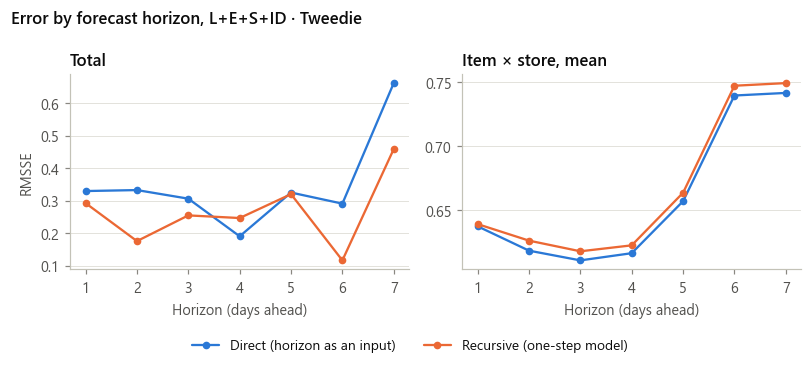

1     2     3     4     5     6     7
direct    Total              0.329 0.332 0.306 0.190 0.325 0.291 0.661
          Item × store, mean 0.637 0.618 0.611 0.617 0.657 0.740 0.742
recursive Total              0.292 0.175 0.254 0.246 0.320 0.116 0.458
          Item × store, mean 0.639 0.626 0.618 0.623 0.664 0.747 0.749

In [12]:
v = max(REC, key=lambda v: list(INPUTS).index(parse(v)[0]))
direct, recursive = by_horizon(fc[v.replace("_recursive", "")]), by_horizon(fc[v])
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3))
for ax, row in zip(axes, direct.index):
    ax.plot(direct.columns, direct.loc[row], color=SERIES[0], marker="o", ms=4, label="Direct (horizon as an input)")
    ax.plot(recursive.columns, recursive.loc[row], color=SERIES[1], marker="o", ms=4, label="Recursive (one-step model)")
    ax.set_title(row)
    ax.set_xlabel("Horizon (days ahead)")
axes[0].set_ylabel("RMSSE")
fig.suptitle(f"Error by forecast horizon, {label(v.replace('_recursive', ''))}", x=0.01, ha="left", fontsize=11,
             fontweight="semibold")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.02), ncols=2)
savefig(fig, "strategy_by_horizon_valid", subdir="global_xgb")
plt.show()
pd.concat({"direct": direct, "recursive": recursive}).round(3)

## 7. Stability across seeds (Section 7.9)

The main model and L+E+S+ID+H are trained again with four other seeds, with the hyperparameters and the number of
rounds of their best trial. The seed changes the row and column subsampling and the horizons drawn for each
origin. Seed 0 is the tuned model.

In [13]:
def seed_table(v):
    t = pd.DataFrame([{"seed": 0, "WRMSSE": best[v]["wrmsse"], **{LEVEL_NAMES[k]: best[v]["wrmsse_by_level"][str(k)] for k in KEEP},
                       "RMSSE mean": best[v]["mean_rmsse"]}] +
                     [{"seed": s["seed"], "WRMSSE": wrmsse_levels(s), **{LEVEL_NAMES[k]: s["wrmsse_by_level"][str(k)] for k in KEEP},
                       "RMSSE mean": s["mean_rmsse"]} for s in json.loads((RESULTS / v / "seeds.json").read_text())]).set_index("seed")
    return pd.concat([t, t.agg(["mean", "std", "min", "max"])])


seeds = pd.concat({label(v): seed_table(v) for v in [TOP, EXTRA]}, names=["variant", "seed"])
seeds.to_csv(RESULTS / "seeds_valid.csv")
seeds.style.format("{:.4f}")

In [14]:
out = rmsse.rename(columns={v: label(v) for v in best}).drop(columns=list(bench))
out.insert(0, "id", stats["id"].to_numpy())
out.to_csv(RESULTS / "rmsse_valid.csv", index=False, float_format="%.5f")
print(f"per-series RMSSE of {out.shape[1] - 1} models saved to {(RESULTS / 'rmsse_valid.csv').relative_to(ROOT)}")

per-series RMSSE of 19 models saved to results\global_xgb\rmsse_valid.csv


## Key findings

All numbers are from the validation window (four weekly origins, 25.04.–22.05.2016.), on which the models were
also tuned, so they are optimistic; the test window is used only in notebook 06. WRMSSE is over the 7
hierarchy levels of the thesis.

1. **Against the classical methods (7.1).** The main model (L+E+S+ID, Tweedie) has WRMSSE 0.556, the
   best classical method (seasonal naive) 0.906. On the mean RMSSE over series the gap is small: 0.739
   against 0.753 for ADIDA. The gain is large on the aggregated levels and small on single series.
2. **Inputs (7.4).** WRMSSE falls from about 0.68 (L) to 0.60 (L+E), stays there with the statistics
   (0.59–0.60 with L+E+S), falls to 0.556 with the identifiers and to 0.539 with the sales of the higher levels. The mean RMSSE moves only from 0.748 to 0.739. The gain of group H is on the aggregated levels (total 0.329 against 0.373) and is larger than the spread between seeds. L+E+S+ID+H has the lowest validation WRMSSE of
   all variants, but it was added after the test window had been opened, so the main model of the thesis
   stays L+E+S+ID and group H is reported as an additional step.
3. **Loss (7.3).** With the same inputs the three losses differ by at most 0.009 in WRMSSE. Five seeds of
   L+E+S+ID range from 0.553 to 0.561 and five seeds of L+E+S+ID+H from 0.539 to 0.545, so the differences
   between the losses are within the spread between seeds.
4. **Pooling (7.2).** With L+E+S, models per store (0.606) and per store × category (0.630) are worse than the global model (0.594) overall: they are better on the store and store × category levels and much worse on the total.
   With L+E+S+ID the global model is the best (0.556, against 0.571 per store, 0.568 per demand class and
   0.595 per store × category): the identifiers give one model what the split gives. The models per series
   follow in notebook 05.
5. **Strategy (7.7).** The recursive model has a lower WRMSSE than the direct one (0.515 against 0.556 with
   L+E+S+ID, 0.573 against 0.594 with L+E+S), because of the top levels (total 0.285 against 0.373). On the
   item × store level and on the mean RMSSE it is slightly worse (0.742 against 0.739). This is one window and
   one seed; the test window has to confirm it.
6. **Limits.** 30 trials per variant, and the search was still improving late in several variants; the models
   per group and the recursive model are not tuned and use the hyperparameters of L+E+S+ID (or L+E+S), not
   of L+E+S+ID+H; seeds were repeated only for L+E+S+ID and L+E+S+ID+H.